Brianna Aceves | DSC 360 | 7.2 Project Milestone 3

For this milestone, I am continuing with the News Category Dataset by Rishabh Misra, which contains HuffPost news articles from 2012 to 2022. My goal is to explore how the language used in news headlines and descriptions relates to their assigned categories. I plan to eventually use this information to build a text classification model that can predict the category of a news article. For this milestone, I will focus on preparing the text and applying different feature engineering techniques, including text normalization, Bag of Words, Bag of N-Grams, and TF-IDF. I will also explore the dataset to identify missing values, duplicates, category distributions, and possible limitations before moving into classification modeling.

In [1]:
#Import libraries for data analysis and visualization

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import re

from collections import Counter

#Import text feature engineering tools
from sklearn.feature_extraction.text import (
    CountVectorizer,
    TfidfVectorizer,
    ENGLISH_STOP_WORDS
)

#Display settings
pd.set_option('display.max_columns', None)

print("Libraries imported successfully!")

Libraries imported successfully!


I started by importing the libraries needed for this milestone. Since this project focuses on news articles and text analysis, I included tools for cleaning text, creating numerical features, and visualizing patterns in the data. I also imported tools from scikit-learn that will allow me to apply Bag of Words, N-Grams, and TF-IDF later in the notebook.

In [2]:
#Load the News Category Dataset
df = pd.read_json(
    "News_Category_Dataset_v3.json",
    lines=True
)

#Check the dataset size
print("Dataset shape:", df.shape)

# Display the first five records
display(df.head())

Dataset shape: (209527, 6)


,link,headline,category,short_description,authors,date
0,https://www.huffpost.com/entry/covid-boosters-...,Over 4 Million Americans Roll Up Sleeves For O...,U.S. NEWS,Health experts said it is too early to predict...,"Carla K. Johnson, AP",2022-09-23
1,https://www.huffpost.com/entry/american-airlin...,"American Airlines Flyer Charged, Banned For Li...",U.S. NEWS,He was subdued by passengers and crew when he ...,Mary Papenfuss,2022-09-23
2,https://www.huffpost.com/entry/funniest-tweets...,23 Of The Funniest Tweets About Cats And Dogs ...,COMEDY,"""Until you have a dog you don't understand wha...",Elyse Wanshel,2022-09-23
3,https://www.huffpost.com/entry/funniest-parent...,The Funniest Tweets From Parents This Week (Se...,PARENTING,"""Accidentally put grown-up toothpaste on my to...",Caroline Bologna,2022-09-23
4,https://www.huffpost.com/entry/amy-cooper-lose...,Woman Who Called Cops On Black Bird-Watcher Lo...,U.S. NEWS,Amy Cooper accused investment firm Franklin Te...,Nina Golgowski,2022-09-22


After loading the News Category Dataset, I found that it contains 209,527 records and 6 columns, which gives me a pretty large amount of text to work with for this project. Looking at the first five records, I noticed that each article includes a link, headline, category, short description, author, and publication date. I also noticed that the articles cover different topics, including U.S. news, comedy, and parenting, which makes me interested in seeing how the language differs between categories. Since my goal is to eventually build a classification model, I think combining the headlines and short descriptions will give me more context than using headlines alone. For now, I plan to focus on those two text columns while keeping the category as my target variable for future modeling.

In [3]:
#Review the dataset structure and data types
print("Dataset Information:")
df.info()

#Check for missing values
print("\nMissing Values:")
print(df.isnull().sum())

#Check for duplicate records
print("\nDuplicate Records:")
print(df.duplicated().sum())

#Count the number of unique news categories
print("\nNumber of Unique Categories:")
print(df['category'].nunique())

Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 209527 entries, 0 to 209526
Data columns (total 6 columns):
 #   Column             Non-Null Count   Dtype         
---  ------             --------------   -----         
 0   link               209527 non-null  object        
 1   headline           209527 non-null  object        
 2   category           209527 non-null  object        
 3   short_description  209527 non-null  object        
 4   authors            209527 non-null  object        
 5   date               209527 non-null  datetime64[ns]
dtypes: datetime64[ns](1), object(5)
memory usage: 9.6+ MB

Missing Values:
link                 0
headline             0
category             0
short_description    0
authors              0
date                 0
dtype: int64

Duplicate Records:
13

Number of Unique Categories:
42


After reviewing the dataset, I found that all 209,527 records have values in each of the six columns, so there are no missing values reported. I was happy to see this because I initially thought I might have to spend more time dealing with missing information, especially in the headlines and descriptions. However, I did find 13 duplicate records, which I plan to remove before beginning feature engineering so they don't affect the results. I also found that the dataset contains 42 different news categories, which is more than I expected. Since my goal is to eventually predict these categories, I think having so many different labels could make classification a little more challenging, especially if some categories contain significantly more articles than others.

Dataset shape after removing duplicates: (209514, 6)
Remaining duplicates: 0

News Category Distribution:


category
POLITICS          35601
WELLNESS          17942
ENTERTAINMENT     17362
TRAVEL             9900
STYLE & BEAUTY     9811
PARENTING          8791
HEALTHY LIVING     6694
QUEER VOICES       6347
FOOD & DRINK       6340
BUSINESS           5992
COMEDY             5400
SPORTS             5077
BLACK VOICES       4583
HOME & LIVING      4320
PARENTS            3955
THE WORLDPOST      3664
WEDDINGS           3653
WOMEN              3571
CRIME              3562
IMPACT             3484
DIVORCE            3426
WORLD NEWS         3299
MEDIA              2944
WEIRD NEWS         2777
GREEN              2622
WORLDPOST          2579
RELIGION           2577
STYLE              2254
SCIENCE            2206
TECH               2100
TASTE              2096
MONEY              1756
ARTS               1509
ENVIRONMENT        1443
FIFTY              1401
GOOD NEWS          1398
U.S. NEWS          1377
ARTS & CULTURE     1339
COLLEGE            1144
LATINO VOICES      1130
CULTURE & ARTS     1074
EDUCATI

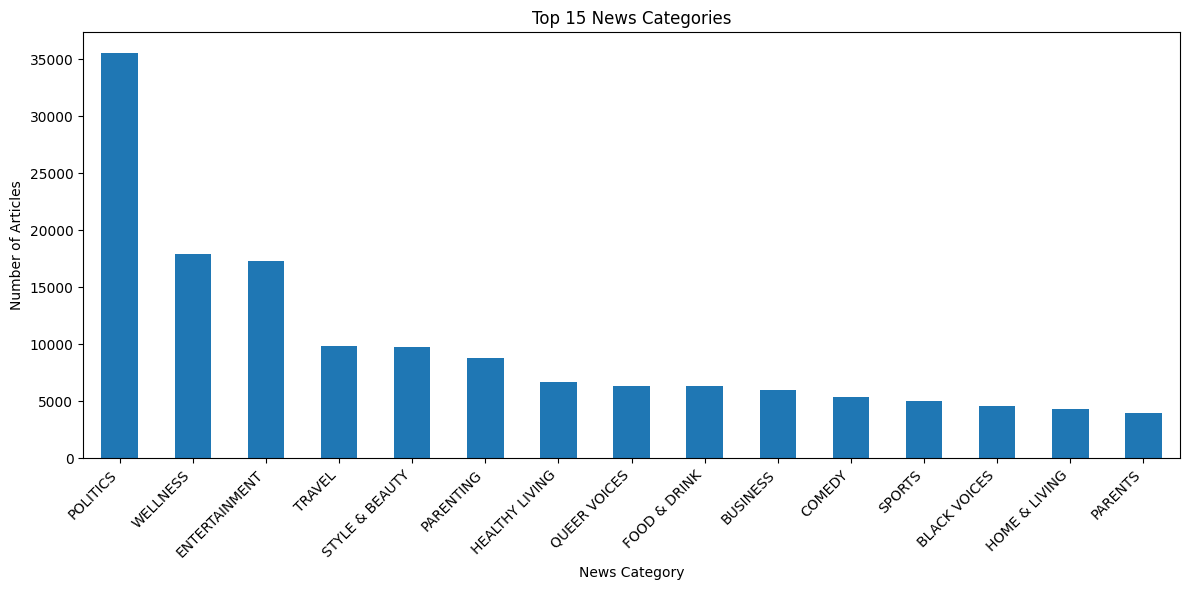

In [4]:
#Remove duplicate records
df = df.drop_duplicates().copy()

#Confirm duplicates were removed
print("Dataset shape after removing duplicates:", df.shape)
print("Remaining duplicates:", df.duplicated().sum())

#Count the articles in each category
category_counts = df['category'].value_counts()

print("\nNews Category Distribution:")
display(category_counts)

#Visualize the 15 most common categories
plt.figure(figsize=(12, 6))

category_counts.head(15).plot(kind='bar')

plt.title("Top 15 News Categories")
plt.xlabel("News Category")
plt.ylabel("Number of Articles")

plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.show()

After finding 13 duplicate records during my initial review, I removed them to avoid counting the same articles more than once. This left me with 209,514 records to work with. I also looked at how the articles were distributed across the 42 news categories and noticed that Politics, Wellness, and Entertainment had the highest number of articles. Some categories appeared much more frequently than others, which makes me think that the dataset may be imbalanced. Since I eventually want to build a classification model, this is something I'll need to consider because categories with fewer examples could be harder for the model to recognize. I thought it was interesting to see how differently the news topics were represented in the dataset.

In [5]:
#Combine headlines and descriptions into one text column

df['combined_text'] = (
    df['headline'].fillna('') + ' ' +
    df['short_description'].fillna('')
).str.strip()

#Compare original and combined text
display(
    df[['headline', 'short_description',
        'combined_text', 'category']].head()
)

,headline,short_description,combined_text,category
0,Over 4 Million Americans Roll Up Sleeves For O...,Health experts said it is too early to predict...,Over 4 Million Americans Roll Up Sleeves For O...,U.S. NEWS
1,"American Airlines Flyer Charged, Banned For Li...",He was subdued by passengers and crew when he ...,"American Airlines Flyer Charged, Banned For Li...",U.S. NEWS
2,23 Of The Funniest Tweets About Cats And Dogs ...,"""Until you have a dog you don't understand wha...",23 Of The Funniest Tweets About Cats And Dogs ...,COMEDY
3,The Funniest Tweets From Parents This Week (Se...,"""Accidentally put grown-up toothpaste on my to...",The Funniest Tweets From Parents This Week (Se...,PARENTING
4,Woman Who Called Cops On Black Bird-Watcher Lo...,Amy Cooper accused investment firm Franklin Te...,Woman Who Called Cops On Black Bird-Watcher Lo...,U.S. NEWS


After looking through the first few news records, I decided to combine the headlines and short descriptions into a single column called "combined_text". I noticed that some of the headlines are fairly short, so I think including the descriptions will give me more information about each article's topic. Since my overall goal is to eventually classify news articles by category, I wanted to make sure I wasn't leaving out text that could help identify patterns. I also kept the original headline, description, and category columns so I can compare the original information with the cleaned text later on in the project.

In [6]:
#Text Normalization
#Create a set of common English stop words
stop_words = set(ENGLISH_STOP_WORDS)

#Define a function to normalize the text
def normalize_text(text):

    # Convert text to lowercase
    text = str(text).lower()

    # Remove URLs
    text = re.sub(r'https?://\S+|www\.\S+', '', text)

    # Remove punctuation and numbers
    text = re.sub(r'[^a-z\s]', ' ', text)

    # Split the text into individual words
    words = text.split()

    # Remove common English stop words
    words = [
        word for word in words
        if word not in stop_words
    ]

    # Join the remaining words back together
    return ' '.join(words)


#Apply text normalization
df['cleaned_text'] = df['combined_text'].apply(normalize_text)

#Compare original and cleaned text
display(
    df[['combined_text', 'cleaned_text']].head()
)

,combined_text,cleaned_text
0,Over 4 Million Americans Roll Up Sleeves For O...,million americans roll sleeves omicron targete...
1,"American Airlines Flyer Charged, Banned For Li...",american airlines flyer charged banned life pu...
2,23 Of The Funniest Tweets About Cats And Dogs ...,funniest tweets cats dogs week sept dog don t ...
3,The Funniest Tweets From Parents This Week (Se...,funniest tweets parents week sept accidentally...
4,Woman Who Called Cops On Black Bird-Watcher Lo...,woman called cops black bird watcher loses law...


For my first feature engineering technique, I focused on normalizing the text so the articles would have a more consistent format. I converted the text to lowercase and removed punctuation, numbers, URLs, and common stop words. I chose to do this because words like "the" and "and" appear frequently but don't necessarily tell me much about an article's topic. By comparing the original text with the cleaned version, I can see how removing unnecessary information makes the text easier to analyze. I'm interested in seeing whether the remaining words will help reveal clearer patterns when I apply Bag of Words and N-Grams.

In [7]:
#Count words remaining after normalization
df['word_count'] = df['cleaned_text'].str.split().str.len()

#Check total cleaned words
total_words = df['word_count'].sum()

print("Total Words After Cleaning:", total_words)

#Remove articles with fewer than 3 cleaned words
df_clean = df[df['word_count'] >= 3].copy()

#Randomly shuffle the records
df_shuffled = df_clean.sample(
    frac=1,
    random_state=42
)

#Calculate the number of records needed for 50,000 words
cumulative_words = df_shuffled['word_count'].cumsum()

minimum_records = (cumulative_words < 50000).sum() + 1

#Aim for 20,000 articles while meeting the word requirement
sample_size = min(
    len(df_shuffled),
    max(20000, minimum_records)
)

#Create the sample
df_sample = df_shuffled.head(sample_size).copy()

#Display sample details
print("Number of Articles in Sample:", len(df_sample))
print("Words in Sample:", df_sample['word_count'].sum())

if df_sample['word_count'].sum() >= 50000:
    print("The sample meets the 50,000-word requirement.")
else:
    print("The sample does NOT meet the requirement.")

Total Words After Cleaning: 3533856
Number of Articles in Sample: 20000
Words in Sample: 338055
The sample meets the 50,000-word requirement.


After normalizing the text, I wanted to make sure my corpus still met the minimum requirement of 50,000 words after stop-word removal. I realized that this requirement refers to the total number of cleaned words, not the number of news articles. And I'm taking the feedback from Week 5 about not doing too large of a data set. Since my dataset originally contained over 209,000 records, I decided to use a random sample of 20,000 articles instead of processing the entire dataset - so it's still large enough to work with but wont fry my laptop. Having said that, I thought this would be a more practical approach. I also used a fixed random state so I could reproduce the same sample if needed. After checking the word counts, my sample contained 324,411 words, which meets the 50,000-word requirement. I think this approach gives me a good balance between having enough text to identify meaningful patterns and keeping the analysis manageable for my computer.

In [8]:
#Create a Bag of Words model using the cleaned text
bow_vectorizer = CountVectorizer(max_features=1000)

#Convert the text into a word frequency matrix
bow_matrix = bow_vectorizer.fit_transform(
    df_sample['cleaned_text']
)

#Get the words and their total frequencies
word_counts = bow_matrix.sum(axis=0).A1

#Create a DataFrame to organize the results
bow_results = pd.DataFrame({
    'Word': bow_vectorizer.get_feature_names_out(),
    'Frequency': word_counts
})

#Sort the words from most to least frequent
bow_results = bow_results.sort_values(
    by='Frequency',
    ascending=False
)

print("Bag of Words Matrix Shape:", bow_matrix.shape)

display(bow_results.head(20))

Bag of Words Matrix Shape: (20000, 1000)


,Word,Frequency
909,trump,1900
590,new,1896
631,people,1256
448,just,1191
887,time,1182
497,like,1121
638,photos,1083
198,day,1067
994,year,1038
495,life,901


For my second feature engineering technique, I used Bag of Words to analyze the most frequently used words in my sample of 20,000 news articles. I limited the model to 1,000 features to keep the analysis manageable. After reviewing the updated results, I noticed that "trump" was the most frequent word, appearing 1,992 times, followed by "new" with 1,918 occurrences. Other common words included "people," "time," and "photos." I thought it was interesting that political terms appeared so frequently, which makes me think political news has a strong presence in my sample. However, I also noticed that several common words were pretty general and could apply to multiple news categories. This reminded me that one limitation of Bag of Words is that it counts how often words appear without considering their meaning or context. I'm curious whether bigrams and TF-IDF will reveal more specific patterns that could be useful for my future classification model.

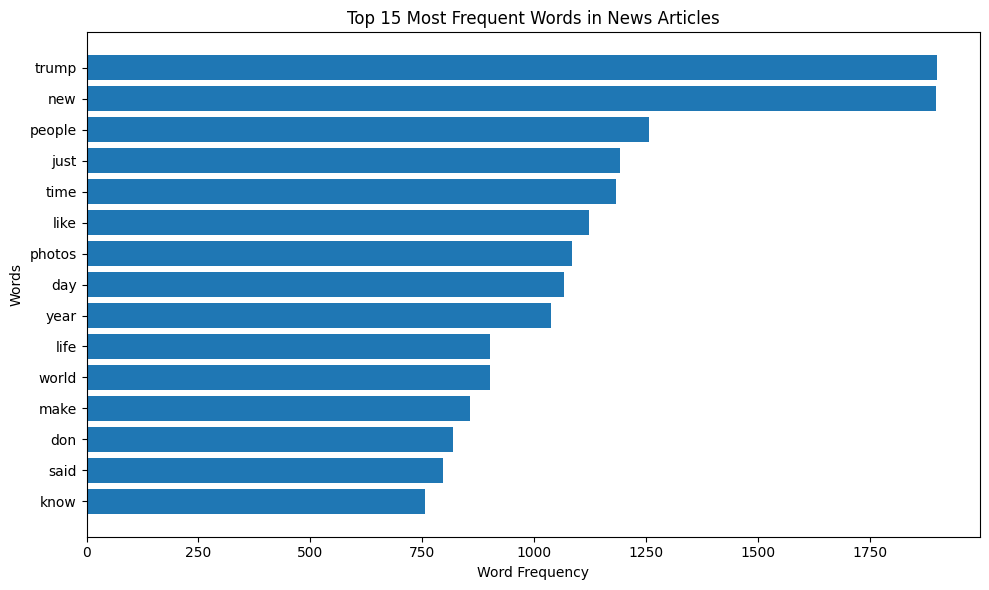

In [9]:
#Select the 15 most frequent words
top_words = bow_results.head(15)

#Create a horizontal bar chart
plt.figure(figsize=(10, 6))

plt.barh(
    top_words['Word'][::-1],
    top_words['Frequency'][::-1]
)

plt.title("Top 15 Most Frequent Words in News Articles")
plt.xlabel("Word Frequency")
plt.ylabel("Words")

plt.tight_layout()
plt.show()

After creating the Bag of Words model, I wanted to visualize the 15 most frequently used words to get a better idea of how often they appeared compared to one another. Looking at the chart, I noticed that "trump" amd "new" appeared much more frequently than the others. I'm curious whether these words are common across several news categories or if they are mainly associated with certain topics. This is something I want to explore further because my overall goal is to eventually classify articles based on their language.

In [10]:
#Create a bigram model
bigram_vectorizer = CountVectorizer(
    ngram_range=(2, 2),
    max_features=1000
)

#Convert cleaned text into bigram frequencies
bigram_matrix = bigram_vectorizer.fit_transform(
    df_sample['cleaned_text']
)

#Calculate the frequency of each bigram
bigram_counts = bigram_matrix.sum(axis=0).A1

#Organize results into a DataFrame
bigram_results = pd.DataFrame({
    'Bigram': bigram_vectorizer.get_feature_names_out(),
    'Frequency': bigram_counts
})

#Sort the most frequently used bigrams
bigram_results = bigram_results.sort_values(
    by='Frequency',
    ascending=False
)

print("Bigram Matrix Shape:", bigram_matrix.shape)

display(bigram_results.head(20))

Bigram Matrix Shape: (20000, 1000)


,Bigram,Frequency
175,donald trump,632
560,new york,318
984,year old,288
951,white house,184
298,hillary clinton,182
284,health care,140
815,supreme court,126
86,check huffpost,104
97,climate change,102
896,united states,102


I used bigrams to see which two-word combinations appeared most frequently in my sample of 20,000 news articles. After reviewing the updated results, I noticed that "donald trump" was the most common combination with 670 occurrences, followed by "new york" with 341 and "year old" with 257. Other common phrases included "hillary clinton," "white house," "health care," and "supreme court." I thought it was interesting that several of the most frequent bigrams were related to politics, which connects to my Bag of Words results where "trump" was the most frequent individual word. Compared to Bag of Words, I think bigrams give me a better idea of what the articles might actually be discussing because the words have more context when paired together. I also noticed that combinations like "check huffpost" seem less useful for identifying a specific news category. This makes me think I may eventually need to consider which features provide the most meaningful information for classification.

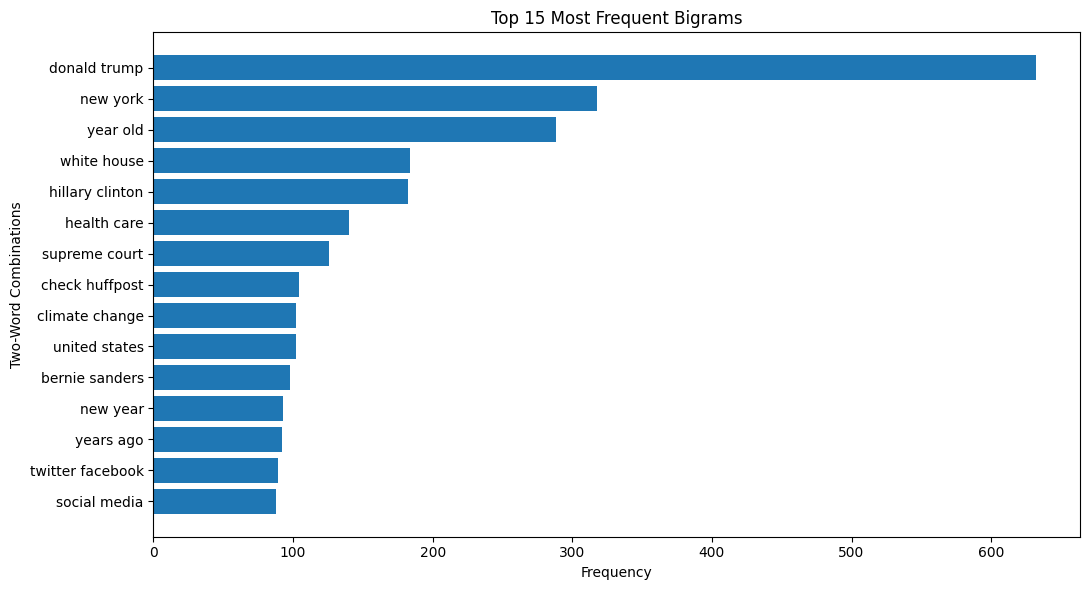

In [11]:
#Select the 15 most frequent bigrams
top_bigrams = bigram_results.head(15)

#Create a horizontal bar chart
plt.figure(figsize=(11, 6))

plt.barh(
    top_bigrams['Bigram'][::-1],
    top_bigrams['Frequency'][::-1]
)

plt.title("Top 15 Most Frequent Bigrams")
plt.xlabel("Frequency")
plt.ylabel("Two-Word Combinations")

plt.tight_layout()
plt.show()

After creating a bar chart of the 15 most common bigrams, I could see how much more frequently certain word combinations appeared compared to others. "Donald trump" stood out the most with 670 occurrences, which was almost twice as many as "new york" with 341. I also noticed that phrases like "hillary clinton," "white house," and "supreme court" appeared frequently, which makes me think political topics are a noticeable part of my sample. Seeing these combinations in a chart made it easier to compare their frequencies. I think this technique could be especially useful for my future classification model because certain phrases may provide clearer clues about an article's topic than individual words alone.

In [12]:
#Create a TF-IDF model with 1,000 features
tfidf_vectorizer = TfidfVectorizer(
    max_features=1000
)

#Convert cleaned text into TF-IDF features
tfidf_matrix = tfidf_vectorizer.fit_transform(
    df_sample['cleaned_text']
)

#Calculate average TF-IDF scores
average_scores = tfidf_matrix.mean(axis=0).A1

#Organize results into a DataFrame
tfidf_results = pd.DataFrame({
    'Word': tfidf_vectorizer.get_feature_names_out(),
    'Average_TFIDF': average_scores
})

#Sort words by their average TF-IDF scores
tfidf_results = tfidf_results.sort_values(
    by='Average_TFIDF',
    ascending=False
)

print("TF-IDF Matrix Shape:", tfidf_matrix.shape)

display(tfidf_results.head(20))

TF-IDF Matrix Shape: (20000, 1000)


,Word,Average_TFIDF
909,trump,0.021879
590,new,0.020034
631,people,0.014204
448,just,0.014047
638,photos,0.013677
497,like,0.013656
887,time,0.013370
198,day,0.012432
994,year,0.012232
988,world,0.011464


I used TF-IDF to look at word importance rather than just counting how frequently words appeared. After reviewing the updated results, I found that "trump" had the highest average TF-IDF score at 0.021879, followed by "new" at 0.020034 and "people" at 0.014204. I thought it was interesting that "trump" and "new" were also the two most frequent words in my Bag of Words results, but "photos" ranked higher in TF-IDF than it did in Bag of Words. I was expecting to see more differences between the techniques, but the overall results were still pretty similar. This helped me realize that TF-IDF doesn't necessarily eliminate common words or completely change which words stand out. Instead, it adjusts their importance based on how frequently they appear across different documents. Since I eventually want to classify news articles, I think it would be interesting to compare how well Bag of Words and TF-IDF perform when used as features in a classification model.

In [20]:
#Identify the five largest news categories in the sample
top_categories = (
    df_sample['category']
    .value_counts()
    .head(5)
    .index
)

#Compare word frequencies across categories
for category in top_categories:

    # Select cleaned articles from the category
    category_text = df_sample.loc[
        df_sample['category'] == category,
        'cleaned_text'
    ]

    #Combine the text and split into individual words
    category_words = ' '.join(category_text).split()

    #Find the ten most common words
    common_words = Counter(
        category_words
    ).most_common(10)

    print("\nCategory:", category)
    print("Number of Articles:", len(category_text))
    print("Most Common Words:")

    for word, count in common_words:
        print(word, ":", count)


Category: POLITICS
Number of Articles: 3450
Most Common Words:
trump : 1443
donald : 478
president : 379
new : 268
gop : 262
clinton : 257
says : 248
said : 224
obama : 214
house : 205

Category: ENTERTAINMENT
Number of Articles: 1690
Most Common Words:
new : 228
star : 130
film : 104
movie : 99
trump : 96
just : 81
time : 74
year : 74
like : 71
says : 68

Category: WELLNESS
Number of Articles: 1667
Most Common Words:
life : 290
health : 229
time : 188
people : 181
new : 171
study : 160
day : 146
just : 129
like : 126
sleep : 121

Category: STYLE & BEAUTY
Number of Articles: 954
Most Common Words:
photos : 421
fashion : 205
style : 197
look : 122
check : 121
week : 119
new : 108
beauty : 107
want : 94
dress : 92

Category: TRAVEL
Number of Articles: 953
Most Common Words:
travel : 187
photos : 178
world : 150
new : 111
best : 110
time : 88
like : 86
city : 80
just : 71
hotels : 71


My first thought is I see s and t as common "words". I believe these are apart of conjunctions, like "that's" and "don't". I'm going to remove single-letter words to prevent future fragments and run again.

In [21]:
#Remove single-letter fragments from the cleaned text

def remove_fragments(text):
    words = text.split()

    # Keep only words with more than one letter
    words = [word for word in words if len(word) > 1]

    return ' '.join(words)

#Apply the additional cleaning to the full dataset
df['cleaned_text'] = df['cleaned_text'].apply(remove_fragments)

#Check the updated text
display(df[['combined_text', 'cleaned_text']].head())

#Verify that single-letter words were removed
single_letters = df['cleaned_text'].str.findall(r'\b[a-z]\b').str.len().sum()

print("Remaining single-letter words:", single_letters)

,combined_text,cleaned_text
0,Over 4 Million Americans Roll Up Sleeves For O...,million americans roll sleeves omicron targete...
1,"American Airlines Flyer Charged, Banned For Li...",american airlines flyer charged banned life pu...
2,23 Of The Funniest Tweets About Cats And Dogs ...,funniest tweets cats dogs week sept dog don un...
3,The Funniest Tweets From Parents This Week (Se...,funniest tweets parents week sept accidentally...
4,Woman Who Called Cops On Black Bird-Watcher Lo...,woman called cops black bird watcher loses law...


Remaining single-letter words: 0


In [22]:
#Rerun
#Update word counts after removing fragments
df['word_count'] = df['cleaned_text'].str.split().str.len()

#Keep articles with at least 3 cleaned words
df_clean = df[df['word_count'] >= 3].copy()

#Create a reproducible sample of 20,000 articles
df_sample = df_clean.sample(
    n=min(20000, len(df_clean)),
    random_state=42
).copy()

#Verify the updated sample
print("Articles in sample:", len(df_sample))
print("Cleaned words in sample:", df_sample['word_count'].sum())

if df_sample['word_count'].sum() >= 50000:
    print("The sample meets the 50,000-word requirement.")
else:
    print("The sample does not meet the 50,000-word requirement.")

Articles in sample: 20000
Cleaned words in sample: 324411
The sample meets the 50,000-word requirement.


After reviewing the most common words across the news categories, I noticed that single letters like "s" and "t" appeared more frequently than I expected. I believe these were leftover fragments from contractions and possessive words after punctuation was removed during normalization. Since these letters don't really provide useful information about an article's topic, I decided to add another cleaning step to remove single-letter words. After applying the change, I confirmed that no single-letter tokens remained in the cleaned text. I also updated my sample so I could rerun the feature engineering techniques with the improved corpus. This helped me realize that text preprocessing sometimes requires going back and making adjustments after reviewing the results.

In [23]:
#Identify the five largest news categories in the sample
top_categories = (
    df_sample['category']
    .value_counts()
    .head(5)
    .index
)

#Compare word frequencies across categories
for category in top_categories:

    # Select cleaned articles from the category
    category_text = df_sample.loc[
        df_sample['category'] == category,
        'cleaned_text'
    ]

    #Combine the text and split into individual words
    category_words = ' '.join(category_text).split()

    #Find the ten most common words
    common_words = Counter(
        category_words
    ).most_common(10)

    print("\nCategory:", category)
    print("Number of Articles:", len(category_text))
    print("Most Common Words:")

    for word, count in common_words:
        print(word, ":", count)


Category: POLITICS
Number of Articles: 3450
Most Common Words:
trump : 1443
donald : 478
president : 379
new : 268
gop : 262
clinton : 257
says : 248
said : 224
obama : 214
house : 205

Category: ENTERTAINMENT
Number of Articles: 1690
Most Common Words:
new : 228
star : 130
film : 104
movie : 99
trump : 96
just : 81
time : 74
year : 74
like : 71
says : 68

Category: WELLNESS
Number of Articles: 1667
Most Common Words:
life : 290
health : 229
time : 188
people : 181
new : 171
study : 160
day : 146
just : 129
like : 126
sleep : 121

Category: STYLE & BEAUTY
Number of Articles: 954
Most Common Words:
photos : 421
fashion : 205
style : 197
look : 122
check : 121
week : 119
new : 108
beauty : 107
want : 94
dress : 92

Category: TRAVEL
Number of Articles: 953
Most Common Words:
travel : 187
photos : 178
world : 150
new : 111
best : 110
time : 88
like : 86
city : 80
just : 71
hotels : 71


After rerunning my category comparison with the improved text, I noticed that the results were much easier to interpret without the single-letter fragments. Politics was still the largest category in my sample with 3,450 articles, followed by Entertainment with 1,690 and Wellness with 1,667. I noticed that the common words matched the categories pretty well. For example, Politics included "trump," "president," and "gop," while Wellness included "health," "study," and "sleep." Style & Beauty had words like "fashion," "style," and "beauty," while Travel included "travel," "world," and "hotels." I also noticed that words like "new" and "photos" appeared across multiple categories, which could make classification more challenging. Overall, I think the updated results show clearer language patterns, and I'm interested in seeing whether these differences will help a classification model recognize the correct news categories.

In [24]:
#Recalculate features after removing single-letter fragments

#Bag of Words
bow_vectorizer = CountVectorizer(max_features=1000)

bow_matrix = bow_vectorizer.fit_transform(
    df_sample['cleaned_text']
)

word_counts = bow_matrix.sum(axis=0).A1

bow_results = pd.DataFrame({
    'Word': bow_vectorizer.get_feature_names_out(),
    'Frequency': word_counts
}).sort_values(
    by='Frequency',
    ascending=False
)

#Bigrams
bigram_vectorizer = CountVectorizer(
    ngram_range=(2, 2),
    max_features=1000
)

bigram_matrix = bigram_vectorizer.fit_transform(
    df_sample['cleaned_text']
)

bigram_counts = bigram_matrix.sum(axis=0).A1

bigram_results = pd.DataFrame({
    'Bigram': bigram_vectorizer.get_feature_names_out(),
    'Frequency': bigram_counts
}).sort_values(
    by='Frequency',
    ascending=False
)

#TF-IDF
tfidf_vectorizer = TfidfVectorizer(max_features=1000)

tfidf_matrix = tfidf_vectorizer.fit_transform(
    df_sample['cleaned_text']
)

average_scores = tfidf_matrix.mean(axis=0).A1

tfidf_results = pd.DataFrame({
    'Word': tfidf_vectorizer.get_feature_names_out(),
    'Average_TFIDF': average_scores
}).sort_values(
    by='Average_TFIDF',
    ascending=False
)

#Display updated results
print("Updated Bag of Words:")
display(bow_results.head(10))

print("\nUpdated Bigrams:")
display(bigram_results.head(10))

print("\nUpdated TF-IDF:")
display(tfidf_results.head(10))

Updated Bag of Words:


,Word,Frequency
910,trump,1992
593,new,1918
635,people,1214
451,just,1198
888,time,1163
497,like,1140
205,day,1106
643,photos,1087
994,year,971
495,life,965



Updated Bigrams:


,Bigram,Frequency
170,donald trump,670
563,new york,341
986,year old,257
302,hillary clinton,204
959,white house,156
288,health care,122
818,supreme court,120
101,climate change,118
87,check huffpost,103
897,united states,102



Updated TF-IDF:


,Word,Average_TFIDF
910,trump,0.022639
593,new,0.020176
643,photos,0.014069
451,just,0.014040
635,people,0.014029
888,time,0.013588
497,like,0.013585
205,day,0.012358
994,year,0.011831
988,world,0.011384


After removing the single-letter fragments, I reran my Bag of Words, bigram, and TF-IDF analyses to see how the results changed. I noticed that "trump" was still the most frequent individual word, increasing from 1,900 occurrences in my earlier results to 1,992 in the updated analysis. The most common bigram was also still "donald trump," increasing from 632 to 670 occurrences. I also found that "trump" continued to have the highest average TF-IDF score, now at 0.022639. I thought it was interesting that the overall patterns stayed pretty similar even though some of the actual frequencies changed. Since I also recreated my random sample after cleaning, I know these differences may reflect both the updated text and changes in which articles were selected. This helped me understand that preprocessing and sampling decisions can affect my findings, even when the most recognizable patterns remain the same.

In [25]:
#Compare the top 10 features from Bag of Words and TF-IDF

comparison = pd.DataFrame({
    'BoW Word': bow_results['Word'].head(10).values,
    'BoW Frequency': bow_results['Frequency'].head(10).values,
    'TF-IDF Word': tfidf_results['Word'].head(10).values,
    'Average TF-IDF': tfidf_results['Average_TFIDF'].head(10).values
})

print("Comparison of Bag of Words and TF-IDF:")

display(comparison)

Comparison of Bag of Words and TF-IDF:


,BoW Word,BoW Frequency,TF-IDF Word,Average TF-IDF
0,trump,1992,trump,0.022639
1,new,1918,new,0.020176
2,people,1214,photos,0.014069
3,just,1198,just,0.014040
4,time,1163,people,0.014029
5,like,1140,time,0.013588
6,day,1106,like,0.013585
7,photos,1087,day,0.012358
8,year,971,year,0.011831
9,life,965,world,0.011384


After rerunning my feature engineering techniques, I wanted to compare Bag of Words and TF-IDF side by side to see whether they highlighted the same words. I noticed that both techniques ranked "trump" and "new" as the top two words, but the rankings started to differ after that. For example, "people" ranked third in Bag of Words, while "photos" ranked third in TF-IDF. I thought this was interesting because I expected TF-IDF to produce more noticeably different results. This comparison helped me understand that even when the same words appear near the top, the techniques measure them differently. Bag of Words counts how frequently words appear, while TF-IDF considers how common they are across documents. Since my next goal is to build a news classification model, I'd like to compare both approaches to see which one helps predict article categories more accurately.

In [26]:
#Final verification of the cleaned corpus and features

final_word_count = (
    df_sample['cleaned_text']
    .str.split()
    .str.len()
    .sum()
)

#Check for remaining single-letter fragments
remaining_fragments = (
    df_sample['cleaned_text']
    .str.findall(r'\b[a-z]\b')
    .str.len()
    .sum()
)

print("Final Number of Articles:", len(df_sample))
print("Final Cleaned Word Count:", final_word_count)
print("Remaining Single-Letter Fragments:", remaining_fragments)

print("\nFeature Matrix Shapes:")
print("Bag of Words:", bow_matrix.shape)
print("Bigrams:", bigram_matrix.shape)
print("TF-IDF:", tfidf_matrix.shape)

#Check the project word-count requirement
if final_word_count >= 50000:
    print("\nThe corpus meets the 50,000-word requirement.")
else:
    print("\nThe corpus does not meet the 50,000-word requirement.")

Final Number of Articles: 20000
Final Cleaned Word Count: 324411
Remaining Single-Letter Fragments: 0

Feature Matrix Shapes:
Bag of Words: (20000, 1000)
Bigrams: (20000, 1000)
TF-IDF: (20000, 1000)

The corpus meets the 50,000-word requirement.


Before wrapping up my milestone, I wanted to double-check that my updated corpus was ready for future modeling. After removing duplicates, normalizing the text, and cleaning up the single-letter fragments, my final sample contained 20,000 articles and 324,411 cleaned words. This is well above the minimum requirement of 50,000 words, so I was able to keep a smaller sample without losing too much information for this stage of the project. I also verified that there were no remaining single-letter fragments and checked the dimensions of my feature matrices. This gave me more confidence that the text was in a usable numerical format and that I could continue working with the same data in my next milestone.

For this milestone, I focused on preparing the News Category Dataset for future classification modeling and exploring different ways to extract useful information from the text. I started with 209,527 news records, removed 13 duplicates, and combined the headlines and short descriptions into one text column. Since the dataset was pretty large, I decided to use a sample of 20,000 articles to make the analysis more manageable while still meeting the 50,000-word requirement. I completed four feature engineering techniques: text normalization, Bag of Words, Bag of N-Grams, and TF-IDF. One thing I found interesting was how frequently political terms appeared in my earlier results, especially "trump" and "donald trump." I also noticed that the different news categories had recognizable vocabulary, which could be helpful for classification. While reviewing my results, I found that single-letter fragments were appearing as common words, so I went back and improved my text cleaning process. This was probably one of the most useful parts of the milestone because it showed me how reviewing my results can help identify issues I initially missed. Overall, I feel like I have a better understanding of how unstructured text can be cleaned and converted into numerical features. For my next milestone, I would like to compare classification models and evaluate how accurately they can predict news categories using the features I've created.